# **1. 지도학습과 강화학습**

### **1-1.  지도학습 (Supervised Learning)**

지도학습은 정답(라벨)이 포함된 데이터로 모델을 학습시키는 방식입니다. 즉, 입력 X와 그에 대응하는 정답 Y를 함께 제공하여, 모델이 X→Y 매핑하는 함수를 학습하도록 합니다. 학습 과정에서는 모델의 예측값과 실제 정답 사이의 오차(loss)를 계산하고, 이를 최소화하도록 가중치를 업데이트합니다. 대표적인 문제 유형은 분류(Classification)와 회귀(Regression)이며, 이미지 분류, 스팸 메일 판별, 주가 예측 등이 이에 해당합니다. 핵심은 "정답이 있는 데이터로 오차를 줄이며 학습한다"는 점입니다.

### **1-2. 강화학습 (Reinforcement Learning)**
강화학습은 정답을 직접 주지 않고, 행동에 대한 보상(Reward)을 통해 학습하는 방식입니다. 에이전트(agent)가 환경(environment)과 상호작용하며 행동(action)을 선택하고, 그 결과로 받은 보상을 최대화하는 방향으로 정책(policy)을 학습합니다. 즉, "이 행동이 좋았는가?"를 보상으로 평가받으며 점점 더 좋은 전략을 찾아갑니다. 게임 AI, 자율주행, 로봇 제어 등이 대표적인 예입니다. 핵심은 "정답 대신 보상을 통해 최적 행동 전략을 학습한다"는 점입니다.

> 강화학습의 개념? 위 말을 위주로 하나하나에 대해 공부하기(공부를 잘 해놔야 나중에 차이남. 최근 경향도 살펴가며 공부하기)

![과제-타워게임과 연결](./images/ref/02_01.png)

### **1-2-1. 보상(Reward)**
- 에이전트가 특정 상태에서 어떤 행동을 했을 때 환경으로부터 받는 즉각적인 피드백 신호
- 행동의 좋고 나쁨을 수치로 표현한 값으로, 에이전트는 이 리워드를 기반으로 자신의 정책을 업데이트하며 장기적인 누적 보상을 최대화하도록 학습
- 매 타임스탭마다 주어질수도 있고, 에피소드 종료 시 한 번만 주어질수도 있음, 그리고 양수는 바람직한 행동을 나타내며 음수는 바람직하지 않은 행동을 의미하는 경우가 일반적임
    - 매 스텝마다 보상을 주는것보다 에피소드가 끝났을 때 한 번만 보상 주는게 더 어려움(보상 계산이 어려운게 아니라, AI가 어떤 행동때문에 보상을 받았는지 알아내기 어렵다는 뜻 - 신용 할당 문제라고 함)
    - 즉각적 피드백: 특정 상태에서 행동했을 때 즉시 주어지는 수치형 피드백
    - 희소성: 리워드는 매 순간 주어지지 않으 수 있음. 많은 환경에서 대부분의 시간 단계에서 보상이 0이고, 특정 목표를 달성했을때만 보상이 주어질 수 있음
    - 지연성: 어떤 행동의 결과에 대한 보상이 즉시 나타나지 않고, 여러 단계를 거친 뒤 나중에 주어질 수 있음. 이로 인해 어떤 행동이 최종 결과에 기여했는지를 파악하기 어려워지며, 이를 신용 할당 문제라고 함(Credit Assignment Problem)
- 강화학습의 목표가 단순히 현재 리워드를 최대화하는 것이 아니라, 할인율을 고려한 미래 보상까지 포함한 누적 리워드를 최대화하는것이 중요(당장 좋은 결과를 얻는 행동보다, 최종적으로 더 좋은 결과를 만드는 행동이 중요 = 매 순간별로 보상 잘 받았다해도 전체 전략이 좋다는거 아니라는 뜻)

> 강화학습의 Reward는 게임 내 재화(Gold)와 다른 개념으로, 에이전트의 행동 결과를 평가하기 위한 학습 신호 (게임 재화를 Reward로 활용할 수도 있지만 반드시 동일할 필요는 없으며, 실제 학습 목표에 맞게 보상 함수를 설계해야함)

### **1-2-2. 에이전트(Agent)**
- 환경과 상호작용하며 상태를 관찰하고, 그에 따라 행동을 선택하고, 그 결과로 리워드를 받아 학습하는 주체를 의미
- 에이전트의 목표는 단기적인 보상이 아니라 미래 보상을 포함한 누적 보상을 최대화하는 정책을 학습하는 것
- 경험을 통해 가치 함수느 정책을 점진적으로 업데이트하며, 탐험과 활용을 균형있게 수행

1. 가치 기반 에이전트
    - 가치 함수를 학습해 행동을 선택하는 방식
    - 각 상태 또는 상태-행동 쌍의 가치를 계산하고, 가치가 가장 높은 행동을 선택
2. 정책 기반 에이전트
    - 행동 선택 규칙인 정책을 직접 학습하는 방식
    - 확률적으로 행동을 출력하는 정책을 최적화함
3. 엑터-크리틱 에이전트
    - 가치 기반과 정책 기반을 결합한 방식
    - Actor는 정책을 학습해 행동을 선택
    - Critic은 가치 함수를 학습해 Actor의 행동을 평가
    
![에이전트별 설명 이미지](./images/ref/02_02.png)

### 1-2-2-a. 몬테주마의 복수

- 보상이 거의 주어지지 안흔 환경에서 스스로 탐험하고 학습할 수 있게 AI를 평가

![몬테주마의 복수 게임 이미지](./images/02_a.png)

### **1-2-3. 탐험**
- 탐험(Exploration)이란, 에이전트가 현재까지 학습한 최적 행동만 반복하는 것이 아니라, 더 나은 보상을 얻을 가능성이 있는 새로운 행동을 시도해보는 과정을 의미
    - 예시) 오늘 BBQ치킨 먹고 너무 맛있었는데, 내일 치킨을 먹을 때 BHC가 더 맛있을수도 있잖아 라고 생각하며 BHC를 먹는것
- 장기적인 누적 보상을 최대화하기 위해 필수적인 전략으로, 이미 잘 알려진 행동을 선택하는 활용과 균형을 이뤄야함

### **1-2-4. 활용**
- 활용(Exploitation)이란, 에이전트가 지그마지의 학습 결과를 바탕으로 현재 가장 높은 보상을 줄것으로 예상되는 행동을 선택하는 과정을 의미
    - 예시) 오늘 BBQ치킨 먹고 너무 맛있었는데, 내일 치킨을 먹을 때 BBQ 맛있었으니 내일도 먹자 라고 생각하며 BBQ를 먹는것
- 이미 경험을 통해 가치가 높다고 판단된 행동을 반복하여 안정적으로 보상을 얻는 전략
- 단기적으로는 높은 성과를 보장하지만, 새로운 가능성을 탐험하지 않기 때문에 더 나은 전략을 발견하지 못하고 지역 최적화에 머무를 위험 있음

> 탐험과 활용이 적절히 균형 이루도록 강화학습 해야함

- 탐험만 하면: 이미 학습한 좋은 행동을 충분히 활용하지 못해 행동이 무작위에 가까워질 수 있음
- 활용만 하면: 더 높은 보상을 얻을 수 있는 새로운 행동을 발견하지 못할 수 있음

___
# **2. 주요 용어를 게임에 대입**

### **2-1. 주요용어**
1. Agent: 선택하는 주체. 캐릭터
2. Environment: 행동에 반응하는 세계. 미로와 벽
3. State: 의사결정에 필요한 현재 정보. 캐릭터의 위치. 열쇠 보유 여부
4. Observation: 실제로 볼 수 있는 정보. 화면의 일부
5. Action: 선택 가능한 조작. 위/아래/좌/우
6. Reward: 한 단계에서 받은 점수. 도착(+10), 충돌(-1)
7. Policy: 상황별 행동 규칙. 갈림길에서 오른쪽 선택
8. Return: 앞으로 받을 보상들의 합. 여러 이동의 총 평가 점수
9. Episode: 시작부터 종료까지 한 판. 출발에서 도착/실패

### 2-2. 보상
- 즉시 보상: 동선을 주우면 +1
- 지연 보상: 바둑은 여러 수를 둔 뒤 승리했을 때 +1점
- 희소 보상: 미로 출구에 도착하기 전까지 0점
- 보상 설계의 함정: 앞으로 잘 이동할때마다 +1점을 주면 출구 대신 계속 왔다갔다 이동만 할 수 있음

> 순차적 의사결정: 지금 장애물을 피하기 위해 돌아가는 행동은 당장은 느리지만, 나중에 목적지에 안전하게 도착할 수 있음
> ε-greedy: 10%는 무작위로 탐험. 나머지 90%는 현재 가장 좋다고 추정한 행동 선택. 최고는 지금까지의 추정치이지 진짜 최고가 아님

# **3. 슬롯머신 AI 개발**
- 가장 많은 보상을 획득하는 AI 에이전트 만들기
- 카지노에 있는 5개의 슬롯머신 중 가장 높은 당첨 확률을 가진 머신을 스스로 찾아내는 AI 프로그램을 개발
- 각 슬롯머신은 서로 다른 당첨 확률을 가지고 있지만, AI 에이전트는 어떤 머신이 가장 유리한지 알지 못함
- 에이전트는 슬롯머신을 직접 선택하고, 당첨 여부를 확인하면서 각 머신의 당첨 확률을 추정해야함
- 최종 목표는 1000번의 행동동안 가능한 많은 보상을 획득하는 것


### 3-1. 슬롯머신 환경 구현
- Python과 Numpy 사용
- 슬롯머신은 총 5개
- 실제 당첨 확률은 [0.2, 0.5, 0.1, 0.8, 0.3]으로 설정
- 슬롯머신을 선택하면 당첨시 1, 실패시 0의 보상을 반환하도록 구현
- AI 에이전트는 실제 당첨 확률을 직접 참조해서 행동하면 안됨

### 3-2. AI 에이전트 구현
- Random 전략: 5ro=개의 슬롯머신 중 하나를 무작위로 선택
- Greedy 전략: 지금까지 획득한 보상을 기반으로 가장 높은 평균 보상을 가진 슬롯머신 선택
- ε-greedy 전략: 일정 확률로 무작위 슬롯머신을 선택하고, 나머지 확률로 현재 가장 높은 평균 보상을 가진 슬롯머신을 선택(ε값은 0.1과 0.01을 각각 적용)

### 3-3. 학습 기능 구현
AI 에이전트는 슬롯머신을 선택할ㄹ때마다 아래 정보를 업데이트 해야하마
- 각 슬롯머신을 선택한 횟수
- 각 슬롯머신의 평균 보상 추정 값
- 매 행동에서 획득한 보상
- 지금까지 획득한 누적 보상

> 평균 보상은 기준 데이터를 모두 다시 계산하지 않고, 이전 평균과 새로 획득한 보상을 이용하는 방식으로 구현

### 3-4. 전략별 실험
각 전략을 1000번씩 실행하고 아래 결과를 출력
- 최종 누적 보상
- 슬롯머신별 선택 횟수
- 슬롯머신별 추정 당첨 확률
- 가장 많이 선택한 슬롯머신 번호

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# 슬롯머신 5개의 실제 당첨 확률
TRUE_PROBS = np.array([0.2, 0.5, 0.1, 0.8, 0.3])

# 스텝 = 1000
N_STEPS = 1000

In [3]:
def bandit_experiment(strategy="epsilon", epsilon=0.1, seed=2026):
    rng = np.random.default_rng(seed)
    counts = np.zeros(5, dtype=int)
    estimates = np.zeros(5, dtype=float)
    rewards = []
    choices = []

    for t in range(N_STEPS):
        if t < 5:
            action = t
        elif strategy == "random":
            action = int(rng.integers(5))
        elif strategy == "greedy":
            action = int(np.argmax(estimates))
        elif strategy == "epsilon":
            action = int(rng.integers(5)) if rng.random() < epsilon else int(np.argmax(estimates))
        else:
            raise ValueError("unknown strategy")

        reward = float(rng.random() < TRUE_PROBS[action])
        counts[action] += 1
        estimates[action] += (reward - estimates[action]) / counts[action]
        rewards.append(reward)
        choices.append(action)
    return np.cumsum(rewards), counts, estimates

In [4]:
results = {
    "Random": bandit_experiment("random"),
    "Greedy": bandit_experiment("greedy"),
    "ε=0.1": bandit_experiment("epsilon", 0.1),
    "ε=0.01": bandit_experiment("epsilon", 0.01)
}

Random   | 누적 보상=376 | 선택 횟수=[184 192 189 201 234] | 추정=[0.2  0.54 0.1  0.8  0.24]
Greedy   | 누적 보상=787 | 선택 횟수=[  7   1   1 990   1] | 추정=[0.29 0.   0.   0.79 0.  ]
ε=0.1    | 누적 보상=772 | 선택 횟수=[ 19  22  19 918  22] | 추정=[0.37 0.32 0.05 0.82 0.32]
ε=0.01   | 누적 보상=791 | 선택 횟수=[  3   2   2 992   1] | 추정=[0.33 0.5  0.   0.8  0.  ]


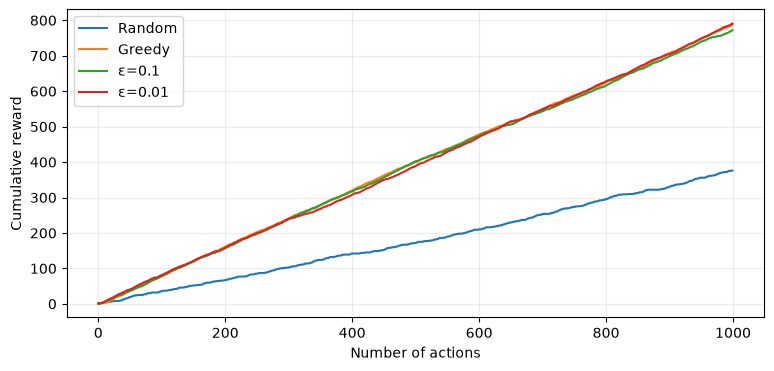

In [5]:
for name, (cumulative, counts, estimates) in results.items():
    print(f"{name:8s} | 누적 보상={cumulative[-1]:.0f} | 선택 횟수={counts} | 추정={estimates.round(2)}")

plt.figure(figsize=(9, 4))

for name, (cumulative, _, _) in results.items():
    plt.plot(cumulative, label=name)

plt.xlabel("Number of actions")
plt.ylabel("Cumulative reward")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

ε=0으로 순수 Greedy 전략이 됨 > 탐험없이 활용만 100%

ε 커지면 탐험배율이 커져 Random 전략이 됨

___
# **4. 마르코프 성질**
'현재 상태와 현재 행동을 알면 다음 상태의 확률을 설명하는데 과거 기록이 추가로 필요하지 않음'
> 현재 상태에 필요한 정보가 모두 포함되어 있다면 과거의 정보 기억할 필요 없음

- 어떤 확률 과정에서 미래 상태가 과거 전체의 이력에 의존하지 않고 오직 현재 상태에만 의존함
- 현재 상태가 과거 정보를 모두 유약하고 있다는 의미

![상태 / 행동 / 마르코프 성질](./images/ref/02_03.png)

### **4-1. MP(Markov Process)**
- 행동을 선택하는 주체가 없다는 것
```
오늘 날씨가 맑으면 내일은 아래와 같이 변한다고 가정
- 맑음 > 맑음(70%)
- 맑음 > 비(30%)
여기엔 누군가가 선택하는 행동 없음
```
> 현재 상태에 따라 다음 상태가 확률적으로 결정되는것을 MP라고 함

```
MP = (S, P)
- S: 상태(맑음, 비)
- P: 상태 전이확률
```

### **4-2. MRP(Markov Reward Process)**
- MP에 보상이라는 개념을 추가한 것

```
맑음 > 맑음 > 비 > 맑음
+10    +10   -5   +10
```

```
MRP = (S, P, R, γ)
- S: 상태
- P: 전이확률
- R: 보상
- γ: 할인률 = 미래에 받을 보상을 현재 기준으로 얼마나 평가할것인지에 대한 값
```

### **4-3. MDP(Markov Decision Process)**
- MRP와의 큰 차이는 에이전트가 직접 행동을 선택할 수 있다는 것
- MRP에 행동 선택이 추가되어 정책을 비교할 수 있다.

```
행동이          성공확률        실패확률        성공보상        실패보상
위로 이동         80%            20%           +10            -10
아래로 이동       60%            40$            +5             -5

기대보상 계산하면 되는데
위로 이동에 대한 기대보상: 0.8(10) + 0.2(-10) = 6
아래로 이동에 대한 기대보상: 0.6(5) + 0.4(-5) = 1
```
> 위와 같은 환경에서 어떤 행동을 선택해야 미래에 많은 보상을 얻을 수 있는지 학습하는것이 강화학습의 핵심임!

![마르코프 과정 / 성질 / 결정 과정](./images/ref/02_04.png)

### **4-4. 전이 확률**
```
로봇이 '오른쪽 이동'을 명령했을 때
- 80%: 오른쪽으로 이동
- 10%: 미끄러져 위쪽으로 이동
- 10%: 제자리 이동
```
> 합계가 100%여야함. 행동을 선택하더라도 다음 상택가 확정되는것 아님

In [6]:
transition = {"right": 0.8, "up": 0.1, "stay": 0.1}
assert np.isclose(sum(transition.values()), 1.0)
rng = np.random.default_rng(7)
samples = rng.choice(list(transition), size=10000, p=list(transition.values()))
for next_state in transition:
    print(next_state, "실험 비율:", round(np.mean(samples == next_state), 3))

right 실험 비율: 0.795
up 실험 비율: 0.101
stay 실험 비율: 0.104


### **4-5. 정책, 상태가치, 행동가치**
- 정책 π: 현재 상태에서 어떤 행동을 할지 결정하는 규칙. 확률적으로 행동을 고를 수도 있음
- 상태 가치 Vπ(s): 지금 이 상태에서 정책을 계속 따르면 앞으로 점수를 평균 얼마나 얻을까?
- 행동 가치 Qπ(s, a): 지금 이 상태에서 먼저 행동을 하고, 이후 정책을 따르면 앞으로 점수를 평균 얼마나 얻을까?

```
예시) 교차로에서 '오른쪽'을 선택한 뒤 목적지에 도착할 가능성이 높다면 그 행동의 Q값이 높을 수 있음
V와 Q는 정책에 따라 달라질 수 있음
```

### **4-6. 할인률 γ와 Return**
```
게임에서 지금 +10점, 다음 턴 +10점, 그 다음 턴 +10점을 받음
- γ=1: 10 + 10 + 10 = 30점 (모두 같은 비중)
- γ=0.9: 10 + 9+ 8.1 = 27.1점
- γ=0.5: 10 + 5 + 2.5 = 17.5점
```
> γ는 '미래의 보상을 현재 평가에서 얼마나 중요하게 볼지'를 정합. γ가 1에 가까우면 미래를 더 오래 고려한다는 뜼이지 미래가 현재보다 더 중요하단 뜻 아님!!!!

In [7]:
rewards = [10, 10, 10]
for gamma in [0.0, 0.5, 0.9, 1.0]:
    discounted = sum((gamma ** t) * reward for t, reward in enumerate(rewards))
    print(f"gamma={gamma:.1f} -> return={discounted:.2f}")

gamma=0.0 -> return=10.00
gamma=0.5 -> return=17.50
gamma=0.9 -> return=27.10
gamma=1.0 -> return=30.00


### 4장 핵심내용 정리 - 마르코프 결정 과정(MDP)
![마르코프 성질·MDP 구성·에이전트 상호작용](./images/ref/02_05.png)

___
# **5. 상태 전이와 할인 보상 계산**
- 일상생활에서 행동을 선택하는 AI 에이전트를 개발하려고 함
- 에이전트는 Working(공부), gym(운동), home(귀가) 세가지 상태를 가지며, 선택한 행동에 따라 상태 변경되고 보상방음

```
현재 상태	행동	다음 상태	보상
working	working	working	+3
working	gym	gym	+5
working	home	home	+12
gym	working	working	+4
gym	home	home	+12
```

### **5-1. 구현 요구시항**
- 상태 전이와 보상을 저장하는 딕셔너리를 작성
- 행동 목록과 할인율을 전달받는 함수 구현
- 시작 상태는 working으로 설정
- 행동을 순서대로 실행하며 상태를 변경하고 보상 저장
- 불가능한 행동을 선택하거나 종료 상태에서 추가 행동을 실행하면 오류가 발생하도록 구현
- 아래 공식을 사용해 할인 리턴율 계산

$
G = R_1 + γR_2 + γ^2R_3 + ...
$

- 할인율을 기본적으로 0.9를 사용
- 두 가지 경로를 실행하고 결과를 비교
    - working > working > home
    - gym > working > home

In [8]:
TRANSITIONS = {
    ("working", "working") : ("working", 3),
    ("working", "gym") : ("gym", 5),
    ("working", "home") : ("home", 12),
    ("gym", "working") : ("working", 4),
    ("gym", "home") : ("home", 12),
}

In [9]:
def evaluate_actions(actions, gamma=0.9):
    state, rewards = "working", []  # 시작 상태

    for action in actions:
        if state == "home":
            raise ValueError("종료 상태 이후 행동이 있습니다.")
        if (state, action) not in TRANSITIONS:
            raise ValueError(f"불가능한 행동: {state} > {action}")
        state, reward = TRANSITIONS[(state, action)]
        rewards.append(reward)
    if state != "home":
        print("주의! 아직 종료되지 않은 경로입니다.")
        
    return rewards, sum(gamma ** t * r for t, r in enumerate(rewards))

In [10]:
for name, actions in {
    "A": ["working", "working", "home"],
    "B": ["gym", "working", "home"]
}.items():
    rewards, G = evaluate_actions(actions)
    print(f"정책 경로 {name}: 보상={rewards}, 할인 리턴={G:.2f}")

정책 경로 A: 보상=[3, 3, 12], 할인 리턴=15.42
정책 경로 B: 보상=[5, 4, 12], 할인 리턴=18.32


___
# **6. 벨만 기대 방정식**
현재 상태의 가치를 계산할 때, 지금 받을 보상과 다음 상태에서 앞으로 받을 보상의 예상 가치를 합치는 공식

1. 학생이 게임을 하고 있다고 가정
- 보상: 특정 행동을 했을 때 즉시 얻는 점수
- 리턴: 지금부터 앞으로 얻을 보상들을 할인해서 합한 값
- 가치: 현재 상태에서 앞으로 얻을 리턴의 기댓값

```
          +2         +10
    시작    >   중간    >   종료

    단순 보상 합계: 2 + 10 = 12
    할인률(0.9) 적용: 2 + 0.9*10 = 11
```
- 왜 벨만 방정식이 필요할까?
    - 위와 같은 예제는 보상이 두 번 밖에 없어서 직접 더하는게 가능하지만
    - 만약 게임이 100번, 1000번 진행된다면 매번 미래의 모든 보상을 직접 나열하는것은 어려움
        - 이걸 벨만 방정식으로 해결 가능!
        - '현재 가치 = 지금 받을 보상 + 할인된 다음 상태의 가치' 이니까
        -  $V(s) = R + γV(s')$

```
    V(A) = 10

    V(S) = 2 + 0.9 * V(A)
    = 2 + 0.9 * 10
    = 11
```

> 미래 보상을 전부 다시 계산하지 않고, 다음 상태의 가치를 이용해 현재 가치를 계산하는 것

- 그럼 다음 상태가 확률적으로 달라질 경우엔?
    - 게임에서 오른쪽 버튼을 눌렀는데, 항상 같은 칸으로 이동하지 않는다 가정
        - 50% 확률로 좋은 칸에 이동
        - 50% 확률로 나쁜 칸에 이동
        - 좋은 칸의 미래 가치는 10점, 나쁜 칸의 미래 가치는 -2점
```
    기댓값을 계산해줘야함(다시)
    10 * 0.5 + (-2) * 0.5
    = 5 -1
    = 4 # 이게 예상가치임

    현재 보상이 0이고, 할인률이 0.9라면
    0 + 0.9 * 4 = 3.6 
    - 여기서 3.6은 실제로 받는 점수가 아님
    - 좋은 칸에 도착하면 할인된 미래 가치는 9점이고, 나쁜 칸에 도착하면 -1.8이 되는대 > 그래서 두 결과를 확률에 따라 평균을 내면 3.6이 되는것임
```
![위 내용 이미지로 풀이](./images/ref/02_06.png)

- 벨만 기대 방정식

- 0단계 : 즉각적인 보상만 고려
$$
V_0(s) = R(s)
$$

- 1단계 : 다음 상태의 가치까지 고려
$$
V_1(s) = R(s) + \gamma \sum_{s'} P(s'|s)V_0(s')
$$

- 2단계 : 두 단계 앞까지 고려
$$
V_2(s) = R(s) + \gamma \sum_{s'} P(s'|s)V_1(s')
$$


$\boxed{V^\pi(s)=\sum_a\pi(a|s)\sum_{s'}P(s'|s,a)[R(s,a,s')+\gamma V^\pi(s')]}$

$R+\gamma V(s')$

$\sum_{s'}P(s'|s,a)[R+\gamma V(s')]$

$\sum_a\pi(a|s)(\text{행동별 기대 가치})$



In [11]:
good_value, bad_value = 10.0, -2.0
gamma = 0.9
expected_next = 0.5 * good_value + 0.5 * bad_value
print("다음 상태 가치의 평균:", expected_next)
print("지금 상태에서 기대하는 가치:", 0 + gamma * expected_next)

다음 상태 가치의 평균: 4.0
지금 상태에서 기대하는 가치: 3.6


___
# **7. 집으로 돌아가는 길**
한 학생이 집으로 돌아가려고 합니다. 현재 위치는 A, B, C중 하나이며, 이동하다 보면 집(Home)에 도착하거나 술집(Bar)에 도착할 수 있습니다. 각 위치에서 다음 위치로 이동할 확률은 미리 정해져있으며, 학생은 이동 방향을 직접 선택할 수 없습니다, 이 환경에서 각 위치가 얼마나 유리한 상태인지 계산하는 프로그램을 작성하세요.

### **7-1. 이동규칙**
```
확률

현재위치        다음위치        이동확률
A               Home            70%
A               B               30%
B               A               50%
B               C               50%
C               B               50%
C               Bar             50%
```

Home과 Bar에 도착 시 이동 종료

보상규칙
- Home 도착 시 +10
- Bar 도착 시 -10
- 그 외 이동 0
- 할인률 0.9


### **7-2. 문제**
- 상태 목록 STATES, 이동 규칙 NEXT, 종료 상태 TERMINAL을 정의
- 다음 위치가 Home이면 +10, Bar이면 -10, 그 외에는 0을 반환하는 함수 작성
- 모든 상태의 가치 0으로 초기화한 후 벨만 기대 방정식 이용해 각 상태의 가치 계산
- 최대 100회 반복. 매 반복하마 A, B, C의 가치를 갱신. 이전 반복과 현재 반복의 최대 가치 차이를 계산. 반복에 따라 가치 변화 출력

### **7-3. 답 할 내용**
1. A, B, C 중 가치가 가장 높은 상태는 어디인가요?
2. A의 가치가 B보다 높은 이유는 무엇인가요?
3. C의 가치가 음수가 되는 이유는 무엇인가요?
4. 반복할수록 가치 변화량이 작아지는 이유는 무엇인가요?
5. 할인율을 0.9에서 1로 변경하면 결과가 어떻게 달라지나요?

### 대답 정리
![정리 이미지](./images/ref/02_09.png)

![게임 설명용 이미지](./images/ref/02_07.png)

In [12]:
STATES = ["Home", "A", "B", "C", "Bar"]

NEXT = {
    "A": [("Home", 0.7), ("B", 0.3)],
    "B": [("A", 0.5), ("C", 0.5)],
    "C": [("B", 0.5), ("Bar", 0.5)]
}

TERMINAL = {"Home", "Bar"}

In [13]:
def arrival_reward(next_state):
    return 1.0 if next_state == "Home" else -1.0 if next_state == "Bar" else 0.0

In [14]:
# 상태 가치 저장 변수 : 모든 상태가치 0으로 초기화
V = {state: 0.0 for state in STATES}

# 100번 반복하는 이유 = A, B, C의 가치가 서로 영향을 주기 때문에
# 반복 계산하면서 각 상태의 가치를 점점 정확하게 갱신하기 위함
for iternation in range(1, 101):
    # 이전 상태가치 복사
    new_V = V.copy()

    for state in ["A", "B", "C"]:
        # 이동 확률과 다음 상태의 가치를 반영해 새로운 가치 계산
        # state: 현재 상태
        # nxt: 다음 상태
        # prob: 전이확률(해당 위치로 이동할 확률)
        # arrival_reward(nxt): 이동 시 보상
        # V[nxt]: 다음 상태의 가치
        # 이거 이중for문으로 작성 가능함 - 블로그에 두가지 버전으로 쓰기
        new_V[state] = sum(prob * (arrival_reward(nxt) + V[nxt]) for nxt, prob in NEXT[state])
    
    # 이전반복과 현재 반복의 상태 가치가 얼마나 달라졌는지 비교 (현재 가치의 최대 차이)
    delta = max(abs(new_V[s] - V[s]) for s in STATES)
    # 이전 반복에서 계산한 새로운 상태 가치를 다음 반복에서 사용할 수 있도록 갱신
    V = new_V

    if iternation in [1, 2, 5, 10, 20, 50, 100]:
        print(f"{iternation:3d}회: A={V['A']:+.4f}, B={V['B']:+.4f}, C={V['C']:+.4f}")
    # 가치 변화가 매우 작으면 반복 종료
    if delta < 1e-12:
        break

# assert: 특정 조건이 참인지 확인 (이거 뭐 프로그램에선 안쓰고..? 파이썬에서 어쩌고..)
# allclose: 두 배열의 값이 허용 오차 범위 내에서 거의 같은지 확인
# atol: 절대 허용 오차 설정
# -> 예상 결과와 계산 결과가 허용 오차 내에서 일치하는지 검증
assert np.allclose([V["A"], V["B"], V["C"]], [0.75, 1/6, -5/12], atol=1e-6) # 100이 안찍히고 중간에 멈추면 멈췄다는거..

  1회: A=+0.7000, B=+0.0000, C=-0.5000
  2회: A=+0.7000, B=+0.1000, C=-0.5000
  5회: A=+0.7420, B=+0.1400, C=-0.4300
 10회: A=+0.7487, B=+0.1650, C=-0.4188
 20회: A=+0.7500, B=+0.1666, C=-0.4167
 50회: A=+0.7500, B=+0.1667, C=-0.4167


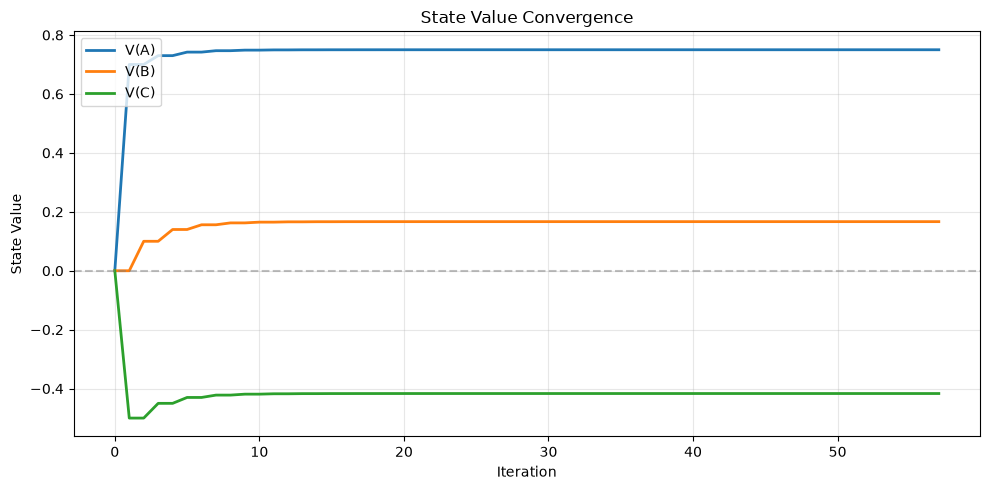

In [15]:
# 내가 확인하기 위한 그래프 - 블로그용
import matplotlib.pyplot as plt

# 상태 가치 초기화
V = {state: 0.0 for state in STATES}

# 반복 횟수와 상태별 가치 기록
iterations = [0]
history = {
    "A": [V["A"]],
    "B": [V["B"]],
    "C": [V["C"]]
}

# 벨만 기대 방정식 반복 계산
for iteration in range(1, 101):
    new_V = V.copy()

    for state in ["A", "B", "C"]:
        new_V[state] = sum(
            prob * (arrival_reward(nxt) + V[nxt])
            for nxt, prob in NEXT[state]
        )

    delta = max(abs(new_V[s] - V[s]) for s in STATES)
    V = new_V

    # 매 반복의 상태 가치 저장
    iterations.append(iteration)

    for state in ["A", "B", "C"]:
        history[state].append(V[state])

    if delta < 1e-12:
        break

# 그래프 출력
plt.figure(figsize=(10, 5))

for state in ["A", "B", "C"]:
    plt.plot(
        iterations,
        history[state],
        label=f"V({state})",
        linewidth=2
    )

plt.axhline(0, color="gray", linestyle="--", alpha=0.5)

plt.title("State Value Convergence")
plt.xlabel("Iteration")
plt.ylabel("State Value")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

여기서 코드 자체가 중요하기 보단 용어와 흐름을 외워야함

난이도가 올라갈텐데 그걸 뭐 알고리즘.. 이런게 있는데

지금 우리가 배우는걸 적절하게 가져다 쓰는게 중요함

한창 파이썬 알고리즘 할때(과제) 그거 기억하고 있으면 쉬울거임 -> 그래프, 거리알고리즘 등..

- A가 Home에 갈 확률?
    - ![image.png](./images/ref/02_08.png)

___
# **8. 몬테카를로 방법**
몬테카를로(Monte Carlo) 방법은 무작위 표본을 반복적으로 생성하고, 그 결과의 평균을 이용해 어떤 값의 기댓값을 추정하는 방법
```
위 예제를 A에서 5번 실행
실행        최종 도착       보상
1             Home         +1
2             Home         +1
3             Bar          -1
4             Home         +1
5             Home         +1

평균 보상: 0.6
```
> 5번만 실행했기때문에 정확하지 않을 수 있지만, 실험 횟수를 10000번 정도로 늘리면 평균값은 이 문제의 이론적 가치인 0.5에 가까워지는 경향이 있음

$
V_\pi(s)\approx\frac{1}{N(s)}\sum_{i=1}^{N(s)}G_i(s)
$

$
G_t=R_{t+1}+\gamma R_{t+2}+\gamma^2R_{t+3}+\cdots
$

### 8-1. 벨만 방정식과 몬테카를로 차리
1. 벨만 방정식
- 계산 원리: 전이 확률로 기대값 계산
- 전이 확률: 필요
- 에피소드: 실행할 필요 없음
- 결과: 수렴한 상태 가치
- 특징: 모델 기반

2. 몬테카를로
- 계산 원리: 실제 경험의 리턴 평균
- 전이 확률: 필요없음
- 에피소드: 종료까지 실행
- 결과: 경험 기반 추정 가치
- 특징: 모델 Free(모델 없어도 사용 가능)

![두 방식 비교](./images/ref/02_10.png)

In [16]:
def random_walk_episode(start, rng):
    state = start
    while state not in TERMINAL:
        options, probs = zip(*NEXT[state])
        state = str(rng.choice(options, p=probs))
    return arrival_reward(state)

In [17]:
rng = np.random.default_rng(2026)
for start in ['A', 'B', 'C']:
    scores = [random_walk_episode(start, rng) for _ in range(10000)]
    print(f'{start}: 몬테카를로 평균={np.mean(scores):+.4f} | 벨만 계산={V[start]:+.4f}')

A: 몬테카를로 평균=+0.7488 | 벨만 계산=+0.7500
B: 몬테카를로 평균=+0.1860 | 벨만 계산=+0.1667
C: 몬테카를로 평균=-0.4152 | 벨만 계산=-0.4167


___
# **9. 5*5 격자**
- (0, 0)은 Home: 도착 시 +1
- (0, 4)는 Bar: 도착 시 -1
- 나머지 칸에서 상/하/좌/우로 이동
- 격자 밖이면 제자리
- 목표 칸에 도착하면 즉시 종료, 종료 상태 가치는 0
- 할인율=0.95: 끝나지 않는 정책에도 계산이 안정적으로 수렴하도록 설정

![문제 격자 환경 정의](./images/ref/02_11.png)

### **9-1. 문제**
1. 상태 집합, 행동 집합, 종료 상태, 보상 규칙을 각각 한 문장으로 정리
2. 각 전이의 다음 상태, 보상, 종료 여부를 구하기
    - (1, 0)에서 up
    - (0, 1)에서 left
    - (0, 3)에서 right
    - (2, 0)에서 left
    - (0, 0)에서 down
3. 한 칸을 갱신하는 식이 왜 네 행동의 평균인지 설명. 종료상태로 들어갈 떄 다음 가치를 0으로 두는 이유도 포함
4. Home과 Bar의 가치가 처음부터 끝까지 0인 이유 코드의 두 지점과 연결해 설명
5. γ=0.95로 실행항 표에서 왼쪽이 양수이고 오른쪽이 음수이며 가운에 열이 0인 이유 설명
6. γ를 0.5로 낮추면 부호는 유지되는가? 절댓값은 어떻게 달라지는가?

In [18]:
SIZE = 5

HOME = (0, 0)
BAR = (0, 4)

GAMMA = 0.95

ACTIONS = {
    "up": (-1, 0),
    "down": (1, 0),
    "left": (0, -1),
    "right": (0, 1)
}

ACTION_NAMES = ['up', 'down', 'left', 'right']

ARROWS = {"up": "↑", "down": "↓", "left": "←", "right": "→", None: "·"}

In [19]:
def grid_step(state, action):

    if state in (HOME, BAR):
        return state, 0.0, True
    
    dr, dc = ACTIONS[action]
    row, col = state
    next_state = (min(max(row+dr, 0), SIZE-1), min(max(col+dc, 0), SIZE-1))

    if next_state == HOME:
        reward = 1.0
    elif next_state == BAR:
        reward = -1.0
    else:
        reward = 0.0

    done = next_state in (HOME, BAR)
    return next_state, reward, done

In [20]:
def show_values(values, digits=3):
    print(np.array2string(np.round(values, digits), formatter={"float_kind": lambda x: f"{x:7.{digits}f}"}))

In [21]:
def show_policy(policy):
    for row in range(SIZE):
        print(" ".join(ARROWS[policy[row, col]] for col in range(SIZE))) 

In [22]:
samples = [
    ((1, 0), "up"),
    ((0, 1), "left"),
    ((0, 3), "right"),
    ((2, 0), "left"),
    ((0, 0), "down")
]

for state, action in samples:
    nxt, reward, done = grid_step(state, action)
    print(f"{state} + {action:5s} -> {nxt}, 보상={reward:+.0f}, 종료={done}")

(1, 0) + up    -> (0, 0), 보상=+1, 종료=True
(0, 1) + left  -> (0, 0), 보상=+1, 종료=True
(0, 3) + right -> (0, 4), 보상=-1, 종료=True
(2, 0) + left  -> (2, 0), 보상=+0, 종료=False
(0, 0) + down  -> (0, 0), 보상=+0, 종료=True


In [23]:
# 랜덤 정책 5×5 격자의 상태가치 계산하는 함수

def evaluate_random_policy(gamma=GAMMA, tol=1e-10, max_iter=10000):

    # 처음엔 각 칸의 가치를 모르니까 전부 0으로 시작!
    values = np.zeros((SIZE, SIZE))

    # 왜 반복할까? 
    # 주변 칸의 가치가 서로 영향을 주기 때문
    for iteration in range(max_iter):
        updated = values.copy()  # 이전 가치를 보존하고 새 값 계산

        # 5×5 격자의 모든 좌표를 하나씩 확인
        for row in range(SIZE):
            for col in range(SIZE):
                state = (row, col)

                # Home과 Bar는 종료 상태니까 갱신할 필요 없음
                if state in (HOME, BAR):
                    continue

                # 상하좌우 행동별 가치 저장할 리스트
                action_values = []

                for action in ACTION_NAMES:
                    # 이동 후 위치, 보상, 종료 여부 확인
                    nxt, reward, done = grid_step(state, action)

                    # 종료되면 미래 보상은 0!
                    future = 0.0 if done else values[nxt]

                    # 즉시 보상 + 할인된 미래 가치
                    action_values.append(reward + gamma * future)

                # 왜 평균일까? 
                # 네 방향을 각각 25% 확률로 선택하기 때문
                updated[state] = np.mean(action_values)

        # 이전 가치와 현재 가치의 차이 중 가장 큰 값 확인
        delta = np.max(np.abs(updated - values))

        # 계산한 값으로 상태가치 갱신
        values = updated

        # 변화가 충분히 작으면 수렴했다고 판단하고 종료
        if delta < tol:
            return values, iteration + 1

    # 최대 반복 횟수까지 수렴하지 못하면 오류 발생
    raise RuntimeError("랜덤 정책 평가가 수렴하지 않음")

In [24]:
random_values, random_iters = evaluate_random_policy()
print("gamma=0.95 반복 횟수: ", random_iters)
show_values(random_values)
assert random_values[HOME] == 0 and random_values[BAR] == 0

low_values, low_iters = evaluate_random_policy(gamma=0.5)
print("gamma=0.5 반복 횟수: ", low_iters)
show_values(low_values)

gamma=0.95 반복 횟수:  109
[[  0.000   0.401   0.000  -0.401   0.000]
 [  0.470   0.236   0.000  -0.236  -0.470]
 [  0.219   0.124   0.000  -0.124  -0.219]
 [  0.110   0.065   0.000  -0.065  -0.110]
 [  0.069   0.042  -0.000  -0.042  -0.069]]
gamma=0.5 반복 횟수:  25
[[  0.000   0.297   0.000  -0.297   0.000]
 [  0.303   0.077   0.000  -0.077  -0.303]
 [  0.047   0.016   0.000  -0.016  -0.047]
 [  0.007   0.003   0.000  -0.003  -0.007]
 [  0.001   0.001   0.000  -0.001  -0.001]]


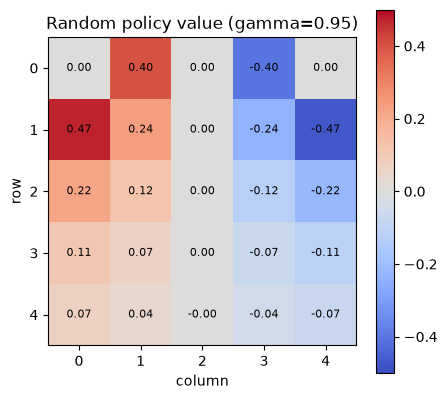

In [25]:
def heatmap(values, title, vmin, vmax):
    plt.figure(figsize=(4.6, 4.2))
    plt.imshow(values, cmap="coolwarm", vmin=vmin, vmax=vmax, origin="upper")
    plt.colorbar()
    plt.title(title)
    plt.xlabel("column")
    plt.ylabel("row")
    plt.xticks(range(SIZE))
    plt.yticks(range(SIZE))
    for row in range(SIZE):
        for col in range(SIZE):
            plt.text(col, row, f"{values[row, col]:.2f}", ha="center", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()


heatmap(random_values, "Random policy value (gamma=0.95)", -0.5, 0.5)

![문제 대답 해설](./images/ref/02_13.png)

그럼 이게 랜덤인데 어떻게 수정할 수 있을까?
- 랜덤정책 : ·하·좌·우를 각각 25% 확률로 선택하는 랜덤 정책
- 해당 좋은 값을 이용해서 더 나은 다음을 선택해서 갈 수 있울듯

___
# **10. 정책 개선**
- 랜덤 정책의 가치는 '마구 걸으면 이 칸이 얼마나 좋은가?'임
- 그 숫자를 이용하면 각 칸에서 더 나은 화살표 고를 수 있음
- Q(s, a) = r + γ * (종료면 0, 아니면 V(s'))
- 개선된 정책은 각 칸에서 이 Q가 가장 큰 행동을 고름. 점수가 같으면 up, down, left, right 중 먼저 나온 행동을 고름

```
미리 생각해보기

탐욕 알고리즘 : 매 순간 선택할 수 있는 것 중 현재 가장 좋아 보이는 선택을 하는 알고리즘

강화학습이랑 연결하면?
기존에는 25%확률로 방향을 선택했지만, 탐욕적 정책으로 네 방향의 Q값 비교해 가장 높은 방향 선택함

어떻게 하는거지?
1. 현재 위치에서 네 방향에 대한 행동가치(Q) 각각 계산하고
2. 즉시 보상과 할인된 다음 상태의 가치 더함
3. 그리고 네 방향 중 Q 값이 가장 높은 행동 선택 -> 달라지는 포인트임!
4. Q값이 같다면 up → down → left → right 순서에서 먼저 나온 행동을 선택

즉, 랜덤으로 움직이는 대신, 기조에 계산한 상태가치 이용해서 가장 유리한 방향을 선택하도록 정책 개선 가능할 것 같음
```

In [26]:
# 현재 상태에서 상·하·좌·우 행동별 Q값을 계산하는 함수

def action_scores(state, values, gamma=GAMMA):
    # state: 현재 위치
    # values: 앞에서 계산한 각 칸의 상태가치
    # gamma: 미래 보상 할인율

    scores = []  # 네 방향의 행동가치를 저장할 리스트

    # 왜 네 방향을 확인할까?
    # 가장 가치가 높은 행동을 찾기 위해서!
    for action in ACTION_NAMES:

        # 행동 후 다음 위치, 보상, 종료 여부 확인 (종료 = 에피소드 종료)
        nxt, reward, done = grid_step(state, action)

        # 종료되면 미래 가치 0, 아니면 다음 칸의 가치 사용
        future = 0.0 if done else values[nxt]

        # Q = 즉시 보상 + 할인된 미래 가치
        scores.append(reward + gamma * future)

    # 상·하·좌·우 순서로 계산된 Q값 반환
    return scores

In [27]:
# 위에서 계산한 Q값 중 가장 높은 행동을 선택해서 정책을 만드는 함수 (각 칸에서 가장 유리한 행동을 선택)

def greedy_policy_from(values, gamma=GAMMA):
    # values: 앞에서 계산한 상태가치
    # gamma: 미래 보상 할인율

    # 5×5 격자에 선택된 행동을 저장할 배열 생성
    # dtype=object: "up", "down" 같은 문자열과 None 저장 가능
    policy = np.empty((SIZE, SIZE), dtype=object)

    # 모든 칸을 하나씩 확인
    for row in range(SIZE):
        for col in range(SIZE):
            state = (row, col)

            # Home과 Bar는 종료 상태니까 행동 선택할 필요 없음
            if state in (HOME, BAR):
                policy[state] = None

            else:
                # 왜 argmax 사용함?
                # 네 방향의 Q값 중 가장 큰 값의 위치를 찾기 위해!
                policy[state] = ACTION_NAMES[
                    int(np.argmax(action_scores(state, values, gamma)))
                ]

    # 각 칸에서 선택한 최선의 행동 반환
    return policy

왜 점수 같으면 먼저 나온 행동 선택함?
- np.argmax()는 최댓값이 여러 개일 때 첫 번째 인덱스를 반환
- p → down → left → right 순서로 우선순위

In [28]:
one_step_policy = greedy_policy_from(random_values)

print('랜덤 정책 가치로 한 번만 개선한 화살표')
show_policy(one_step_policy)

랜덤 정책 가치로 한 번만 개선한 화살표
· ← ← ← ·
↑ ← ← ← ↓
↑ ↑ ← ← ↓
↑ ↑ ← ← ←
↑ ← ← ← ←


In [29]:
for action, score in zip(ACTION_NAMES, action_scores((1, 4), random_values)):
    print(f"{action:5s} {score:_.3f}")

up    -1.000
down  -0.208
left  -0.224
right -0.446


# **11. 정책 반복**
더이상 전책이 바뀌지않을 때 까지 계속 반복해서 최적의 방법을 찾음

정책 반복은 두 단계를 정책이 변하지 않을때까지 반복
1. 정책 평가: 지금 화살표를 고정하고, 그 화살표만 따르는 V가 수렴할때까지 반복 계산
2. 정책 개선: 그 v로 각 칸의 화살표를 다시 그림(상하좌우 Q값 비교, 가장 높은 Q값 가진 방향으로 화살표 변경)

> 평가 > 개선 > 비교 > 다시평가(반복)


In [30]:
# 현재 정책(화살표) 고정하고 각 칸의 가치 평가하는 함수

def evaluate_policy(policy, gamma=GAMMA, tol=1e-10, max_iter=10000):

    # 모든 칸의 가치를 0으로 초기화
    values = np.zeros((SIZE, SIZE))

    # 왜 반복할까? 
    # 주변 칸의 가치가 서로 영향을 주기 때문!
    for iteration in range(max_iter):
        updated = values.copy()  # 이전 가치 보존

        # 격자의 모든 칸 확인
        for row in range(SIZE):
            for col in range(SIZE):
                state = (row, col)

                # 종료 상태는 더 이상 계산하지 않음
                if state in (HOME, BAR):
                    continue

                # 랜덤 선택 X → 현재 정책이 정한 방향으로 이동
                nxt, reward, done = grid_step(state, policy[state])

                # 종료되면 미래 가치 0, 아니면 다음 칸의 가치 사용
                future = 0.0 if done else values[nxt]

                # 현재 보상 + 할인된 미래 가치
                updated[state] = reward + gamma * future

        # 이전 값과 새 값의 최대 차이 계산
        delta = np.max(np.abs(updated - values))

        values = updated  # 새 가치로 갱신

        # 값이 충분히 안정되면 계산 종료
        if delta < tol:
            return values, iteration + 1

    # 최대 반복 횟수 내에 수렴하지 않으면 오류
    raise RuntimeError("정책 평가가 수렴되지 않았음")

위 코드에서 중요한건?
- policy[state]: 랜덤이 아니라 현재 정책에서 정해진 방향을 사용한다.
- delta < tol: 정책 자체를 변경하는 게 아니라 상태가치 V가 수렴했는지 확인한다.

In [31]:
# 정책이 바뀐건지 안바뀐건지 확인하는 용도
def policies_equal(left, right):
    return all(left[r, c] == right[r, c] for r in range(SIZE) for c in range(SIZE))

In [32]:
# 정책 평가와 개선을 반복해 최적 정책을 찾는 함수
def policy_iteration(gamma=GAMMA, max_outer=20):

    # 처음에는 모든 칸을 오른쪽으로 이동하도록 설정
    # 왜 right일까? 
    # 정책 반복을 시작하려면 초기 정책이 필요하기 때문!
    policy = np.full((SIZE, SIZE), 'right', dtype=object)

    # Home과 Bar는 종료 상태니까 행동할 필요 없음
    policy[HOME] = None
    policy[BAR] = None

    # 왜 반복할까? 
    # 정책을 개선하면 상태가치도 달라지기 때문!
    for outer in range(1, max_outer + 1):

        # 1. 정책 평가: 현재 화살표대로 이동했을 때의 가치 계산
        # eval_iters: 상태가치가 수렴하기까지 반복한 횟수
        values, eval_iters = evaluate_policy(policy, gamma=gamma)

        # 2. 정책 개선: 각 칸에서 Q값이 가장 높은 방향 선택
        improved = greedy_policy_from(values, gamma=gamma)

        # 바깥 반복 횟수와 정책 평가 반복 횟수 출력
        print(f"바깥 {outer}회 / 평가 반복 = {eval_iters}")

        # 개선된 정책의 화살표 확인
        show_policy(improved)

        # 왜 비교할까? 화살표가 더 이상 바뀌지 않으면 종료하기 위해!
        if policies_equal(policy, improved):
            return values, improved, outer

        # 정책이 달라졌다면 개선된 정책으로 교체
        policy = improved

    # 최대 20회 안에 정책이 안정되지 않으면 오류 발생
    raise RuntimeError("정책 반복이 끝나지 않음")

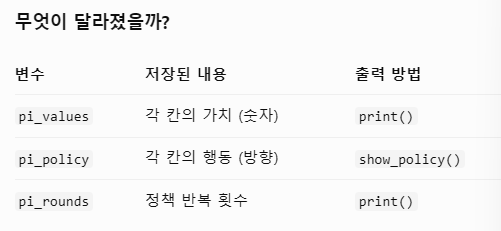

In [33]:
pi_values, pi_policy, pi_rounds = policy_iteration()

print("정책 반복 최종 가치")
show_values(pi_values)

print("정책 반복 최종 정책")
show_policy(pi_policy)

# 반복 횟수 출력
print("정책 반복 횟수:", pi_rounds)

바깥 1회 / 평가 반복 = 4
· ← ↓ ↓ ·
↑ ↓ ↓ ↓ ↓
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
바깥 2회 / 평가 반복 = 5
· ← ← ↑ ·
↑ ↑ ↑ ↑ ↓
↑ ← ↑ ↑ ↑
↑ ← ↑ ↑ ↑
↑ ← ↑ ↑ ↑
바깥 3회 / 평가 반복 = 7
· ← ← ← ·
↑ ↑ ↑ ← ↓
↑ ↑ ↑ ← ↑
↑ ↑ ↑ ← ↑
↑ ↑ ↑ ← ↑
바깥 4회 / 평가 반복 = 8
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ←
바깥 5회 / 평가 반복 = 9
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
바깥 6회 / 평가 반복 = 9
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
정책 반복 최종 가치
[[  0.000   1.000   0.950   0.902   0.000]
 [  1.000   0.950   0.902   0.857   0.815]
 [  0.950   0.902   0.857   0.815   0.774]
 [  0.902   0.857   0.815   0.774   0.735]
 [  0.857   0.815   0.774   0.735   0.698]]
정책 반복 최종 정책
· ← ← ← ·
↑ ↑ ↑ ↑ ←
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
↑ ↑ ↑ ↑ ↑
정책 반복 횟수: 6
